# PrivateGGM Demo

This notebook demonstrates how to run iterative private covariance estimation experiments on both **synthetic** and **real** datasets.

## Overview

1. **Estimates the diagonal** with privacy budget `ρ_v = α·ρ`
2. **Selects off-diagonal entries** to measure using MaxEnt criterion with budget `ρ_s = (1-α)·ρ·0.1`
3. **Measures selected entries** with privacy budget `ρ_c = (1-α)·ρ·0.9`
4. **Reconstructs the full covariance** using maximum entropy estimation

We compare against the **SSP baseline** which adds noise to all entries in a "data-independent".

## 1. Imports

In [1]:
import numpy as np
import json
import os
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from privateggm.data import (
    generate_well_conditioned_gaussian,
    load_data,
    compute_and_save_bounds,
    load_and_process_data,
    rescale_data
)
from privateggm.driver import run_iterative_mode
from privateggm.utils import (
    mahalanobis_cov_error,
    frobenius_error
)
from privateggm.privacy import SSP_covariance, cov_sensitivity_l2, cov_sensitivity_linf

## 2. Configure Experiment Parameters

Set your experiment configuration here:

In [2]:
# ============================================================================
# EXPERIMENT SETUP
# ============================================================================

# Data type
DATA_TYPE = 'synthetic'  # Options: 'synthetic' or 'real'
DATA_NAME = None         # If 'real', choose from: 'Adult', 'SeoulBikeData', 'LifeExpectancy','BreastCancerWisconsin')

# Synthetic data parameters (only used if DATA_TYPE='synthetic')
DIMENSION = 10           # Dimension d
N_SAMPLES = 1000         # Number of samples

# Privacy parameters
RHO_VALUES = [0.0001, 0.001, 0.01, 0.1, 1.0, 2.0, 5.0, 10.0]  # Privacy budgets to test
ALPHA = 0.2              # Budget split: fraction for diagonal (0.2 = 20%)

# Iterative algorithm parameters
OFF_DIAG_PCT = 0.3       # Proportion of off-diag entries to measure (0.3 = 30%)

# Experiment parameters
N_TRIALS = 1             
SENSITIVITY_TYPE = 'linf'  
RESCALE = True           # whether to rescale data to [-1,1]
SEED = 42                # Random seed for reproducibility

# ============================================================================

print("Experiment Configuration:")
print(f"  Data Type: {DATA_TYPE}")
if DATA_TYPE == 'synthetic':
    print(f"  Dimension: {DIMENSION}")
    print(f"  Samples: {N_SAMPLES}")
else:
    print(f"  Dataset: {DATA_NAME}")
print(f"  Off-diagonal %: {OFF_DIAG_PCT*100:.0f}%")
print(f"  Alpha (diagonal budget): {ALPHA}")
print(f"  Number of trials: {N_TRIALS}")
print(f"  Privacy budgets: {RHO_VALUES}")

Experiment Configuration:
  Data Type: synthetic
  Dimension: 10
  Samples: 1000
  Off-diagonal %: 30%
  Alpha (diagonal budget): 0.2
  Number of trials: 1
  Privacy budgets: [0.0001, 0.001, 0.01, 0.1, 1.0, 2.0, 5.0, 10.0]


## 3. Load and Process Data

This section handles both synthetic data generation and real data loading.

In [3]:
# Set random seed based on global SEED
rng = np.random.default_rng(SEED)

# Data directory
data_dir = Path('../data')
data_dir.mkdir(exist_ok=True)

if DATA_TYPE == 'synthetic':
    print(f"\n{'='*80}")
    print(f"Generating synthetic data with d={DIMENSION},n={N_SAMPLES}")
    print(f"{'='*80}\n")
    
    # Generate synthetic data
    df = generate_well_conditioned_gaussian(
        rng=rng,
        outdir=str(data_dir),
        n_samples=N_SAMPLES,
        d=DIMENSION,
        rescale=RESCALE
    )
    
    data_path = data_dir / f"synthdata{DIMENSION}rescale{RESCALE}.csv"
    bounds_path = data_dir / f"L_bounds_rescale{RESCALE}.json"
    
    # Process the data
    processed_data, actual_n, actual_d, Sigma_true, T = load_and_process_data(
        str(data_path), str(bounds_path), clip_type=SENSITIVITY_TYPE, rescale=RESCALE)
    X = processed_data.to_numpy()
    d = DIMENSION
    
else:  # Real data
    print(f"\n{'='*80}")
    print(f"Loading real dataset: {DATA_NAME}")
    print(f"{'='*80}\n")
    
    # Load target columns configuration
    target_columns_path = Path('../target_columns.json')
    target_col = None
    
    if target_columns_path.exists():
        with open(target_columns_path, 'r') as f:
            target_columns = json.load(f)
        target_col = target_columns.get(DATA_NAME, None)
        print(f"Target column: {target_col}")
    
    # Load the data
    data_df = load_data(str(data_dir), data_name=DATA_NAME, target_column=target_col)
    
    # Handle missing values
    print(f"Original data shape: {data_df.shape}")
    print(f"Missing values: {data_df.isnull().sum().sum()}")
    data_df = data_df.dropna()
    print(f"Data shape after dropping NaNs: {data_df.shape}")
    
    # Compute bounds and save
    bounds_path = compute_and_save_bounds(data_df, str(data_dir), rescale=RESCALE)
    
    # Apply rescaling
    if RESCALE:
        data_df = rescale_data(data_df)
    
    # Save processed data
    temp_data_path = data_dir / f"{DATA_NAME}_processed_rescale{RESCALE}.csv"
    data_df.to_csv(temp_data_path, index=False)
    
    # Process data
    processed_data, actual_n, actual_d, Sigma_true, T = load_and_process_data(
        str(temp_data_path), str(bounds_path), clip_type=SENSITIVITY_TYPE, rescale=RESCALE
    )
    
    X = processed_data.to_numpy()
    _, d = X.shape

# Print data statistics
print(f"\n{'='*80}")
print("Data Statistics:")
print(f"{'='*80}")
print(f"  Shape: {X.shape}")
print(f"  Dimension (d): {d}")
print(f"  Samples (n): {X.shape[0]}")
print(f"  Data range: [{X.min():.3f}, {X.max():.3f}]")
print(f"  Data mean: {X.mean():.3f}")
print(f"  Data std: {X.std():.3f}")
print(f"  Sensitivity bound T: {T:.3f}")
print(f"  NaNs: {np.isnan(X).sum()}")
print(f"  Infs: {np.isinf(X).sum()}")


Generating synthetic data with d=10,n=1000

Analytical bounds: L2=3.162, Linf=1

Data Statistics:
  Shape: (1000, 10)
  Dimension (d): 10
  Samples (n): 1000
  Data range: [-1.000, 1.000]
  Data mean: 0.004
  Data std: 0.324
  Sensitivity bound T: 1.000
  NaNs: 0
  Infs: 0
Analytical bounds: L2=3.162, Linf=1

Data Statistics:
  Shape: (1000, 10)
  Dimension (d): 10
  Samples (n): 1000
  Data range: [-1.000, 1.000]
  Data mean: 0.004
  Data std: 0.324
  Sensitivity bound T: 1.000
  NaNs: 0
  Infs: 0


## 4. Setup Experiment Parameters

Calculate the number of measurements and sensitivity for SSP baseline.

In [4]:
# Compute SSP baseline sensitivity
n_samples, d = X.shape
if SENSITIVITY_TYPE == 'l2':
    ssp_sensitivity = cov_sensitivity_l2(n_samples, T)
else:  # linf
    ssp_sensitivity = cov_sensitivity_linf(n_samples, d, T)

# Compute number of measurements from off_diag_pct
n_offdiag_total = d * (d - 1) // 2
n_measurements = int(OFF_DIAG_PCT * n_offdiag_total)

print(f"\n{'='*80}")
print("Iterative mode parameters:")
print(f"{'='*80}")
print(f"  Off-diagonal percentage: {OFF_DIAG_PCT:.1%}")
print(f"  Total off-diagonal entries: {n_offdiag_total}")
print(f"  Number of measurements: {n_measurements}")
print(f"  SSP sensitivity: {ssp_sensitivity:.6f}")
print(f"\nBudget Split (α={ALPHA}):")
print(f"  Diagonal: ρ_v = {ALPHA}·ρ = {ALPHA:.2f}ρ")
print(f"  Selection: ρ_s = (1-{ALPHA})·ρ·0.1 = {(1-ALPHA)*0.1:.2f}ρ")
print(f"  Measurement: ρ_c = (1-{ALPHA})·ρ·0.9 = {(1-ALPHA)*0.9:.2f}ρ")


Iterative mode parameters:
  Off-diagonal percentage: 30.0%
  Total off-diagonal entries: 45
  Number of measurements: 13
  SSP sensitivity: 0.014142

Budget Split (α=0.2):
  Diagonal: ρ_v = 0.2·ρ = 0.20ρ
  Selection: ρ_s = (1-0.2)·ρ·0.1 = 0.08ρ
  Measurement: ρ_c = (1-0.2)·ρ·0.9 = 0.72ρ


## 5. Run Experiments Across Privacy Budgets

This is the main experiment loop that runs the iterative algorithm and SSP baseline for each privacy budget.

In [ ]:
# Initialize results dictionary
results = {
    'parameters': {
        'd': d,
        'n': n_samples,
        'rho_values': RHO_VALUES,
        'off_diag_pct': OFF_DIAG_PCT,
        'alpha': ALPHA,
        'n_trials': N_TRIALS,
        'sensitivity_type': SENSITIVITY_TYPE,
        'rescale': RESCALE,
        'seed': SEED
    },
    'results': {}
}

print(f"\n{'='*80}")
print("Running Experiments")
print(f"{'='*80}\n")

# Loop over rho values
for rho in RHO_VALUES:
    print(f"\n{'='*80}")
    print(f"Testing ρ = {rho}")
    print(f"{'='*80}")
    
    if rho not in results['results']:
        results['results'][rho] = []
    
    for trial in range(N_TRIALS):
        print(f"\nTrial {trial + 1}/{N_TRIALS}", end=" ... ")
        
        try:
            # Create RNG for this trial
            trial_rng = np.random.default_rng(seed=trial * 1000 + 42)
            
            # Run iterative algorithm
            Sigma_est, model = run_iterative_mode(
                rng=trial_rng,
                d=d,
                X=X,
                n_measurements=n_measurements,
                rho=rho,
                alpha=ALPHA,
                sensitivity_type=SENSITIVITY_TYPE,
                bound=T
            )
            
            # Compute errors for iterative method
            mah_error = mahalanobis_cov_error(Sigma_true, Sigma_est)
            frob_error = frobenius_error(Sigma_true, Sigma_est)
            
            # Compute SSP baseline with same privacy budget
            Sigma_SSP, ssp_noise_scale = SSP_covariance(Sigma_true, ssp_sensitivity, rho, rng=trial_rng)
            mah_error_ssp = mahalanobis_cov_error(Sigma_true, Sigma_SSP)
            frob_error_ssp = frobenius_error(Sigma_true, Sigma_SSP)
            
            # Get actual noise scales from the model
            diag_noise_scale = model.actual_diag_noise_scale
            offdiag_noise_scale = model.actual_offdiag_noise_scale
            
            # Store results
            trial_results = {
                'iterative': {
                    'mahalanobis_error': float(mah_error),
                    'frobenius_error': float(frob_error),
                    'estimated_cov': Sigma_est.tolist(),
                    'diag_noise_scale': float(diag_noise_scale),
                    'offdiag_noise_scale': float(offdiag_noise_scale),
                    'n_measured_offdiag': int(n_measurements),
                    'n_total_offdiag': int(d * (d-1) // 2)
                },
                'ssp': {
                    'mahalanobis_error': float(mah_error_ssp),
                    'frobenius_error': float(frob_error_ssp),
                    'estimated_cov': Sigma_SSP.tolist(),
                    'noise_scale': float(ssp_noise_scale)
                },
                'true_cov': Sigma_true.tolist()
            }
            
            results['results'][rho].append(trial_results)
            
            print(f"Results:")
            print(f"    Iterative: Mah={mah_error:.4f}, Frob={frob_error:.4f}")
            print(f"    SSP:       Mah={mah_error_ssp:.4f}, Frob={frob_error_ssp:.4f}")
            print(f"    Ratio: {frob_error/frob_error_ssp:.3f}× (lower is better)")
            
        except Exception as e:
            print(f"Error: {str(e)}")
            import traceback
            traceback.print_exc()
            continue

print(f"\n{'='*80}")
print("Experiments Complete!")
print(f"{'='*80}")


Running Experiments


Testing ρ = 0.0001

Trial 1/1 ... %%%%% noise scale PGD-MaxEnt (diagonal): 1.0 %%%%%
%%%%% noise scale PGD-MaxEnt (measurement): 0.6009252125773316 %%%%%
Iteration 1/13
Selected entry (1,9) with score 0.017574
Empirical: 0.017574, Noisy: 0.484968, Noise std: 0.600925
Iteration 2/13
Selected entry (1,9) with score 0.017574
Empirical: 0.017574, Noisy: 0.484968, Noise std: 0.600925
Iteration 2/13
Selected entry (3,8) with score 0.010087
Empirical: 0.010087, Noisy: 0.687475, Noise std: 0.600925
Iteration 3/13
Selected entry (3,8) with score 0.010087
Empirical: 0.010087, Noisy: 0.687475, Noise std: 0.600925
Iteration 3/13
Selected entry (2,6) with score 0.012151
Empirical: 0.012151, Noisy: -0.504220, Noise std: 0.600925
Iteration 4/13
Selected entry (2,6) with score 0.012151
Empirical: 0.012151, Noisy: -0.504220, Noise std: 0.600925
Iteration 4/13
Selected entry (3,4) with score 0.016869
Empirical: 0.016869, Noisy: -0.559347, Noise std: 0.600925
Iteration 5/13
Selecte

## 6. Save Results

Save the experimental results to a JSON file for later analysis.

In [7]:
# Create output directory
output_dir = Path('results/iterative')
output_dir.mkdir(parents=True, exist_ok=True)

# Filename
dataset_name = DATA_NAME if DATA_TYPE == 'real' else 'synthetic'
output_file = output_dir / f'iterative_privacy_analysis_{dataset_name}_d{d}_offdiag{OFF_DIAG_PCT}_alpha{ALPHA}.json'

# Save results
with open(output_file, 'w') as f:
    json.dump(results, f, indent=2)

print(f"\n{'='*80}")
print(f"Results saved to: {output_file}")
print(f"{'='*80}")


Results saved to: results/iterative/iterative_privacy_analysis_synthetic_d10_offdiag0.3_alpha0.2.json


## 7. Visualize Results

Plot the comparison between Iterative and SSP methods.

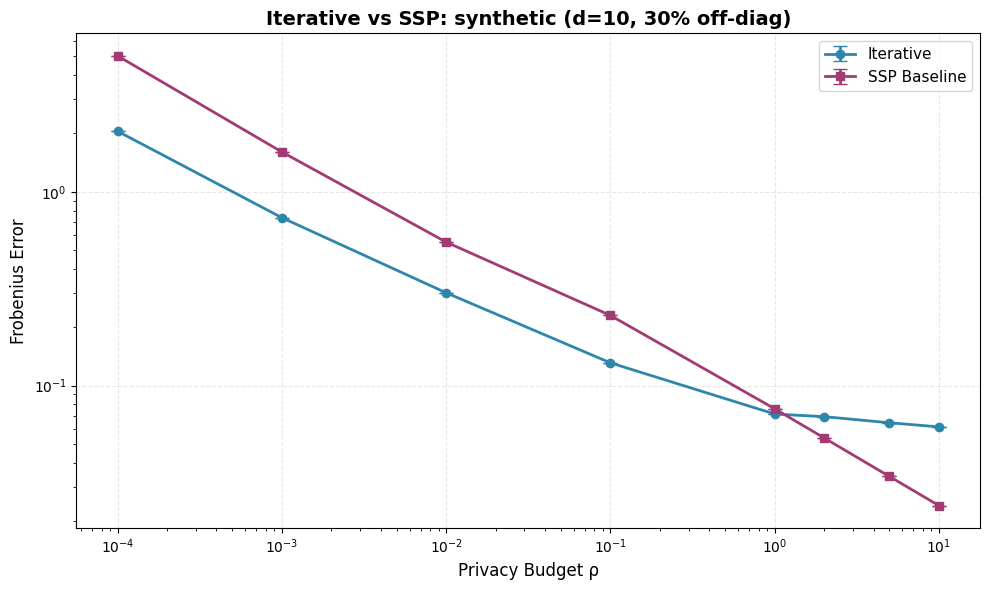


 Plot saved to: results/iterative/plot_synthetic_d10_offdiag0.3_alpha0.2.pdf


In [8]:
# Extract data for plotting
rho_values = []
iterative_means = []
iterative_stds = []
ssp_means = []
ssp_stds = []

for rho_key in sorted(results['results'].keys(), key=lambda x: float(x)):
    rho_val = float(rho_key)
    rho_values.append(rho_val)
    
    trials = results['results'][rho_key]
    iter_errors = [t['iterative']['frobenius_error'] for t in trials]
    ssp_errors = [t['ssp']['frobenius_error'] for t in trials]
    
    iterative_means.append(np.mean(iter_errors))
    iterative_stds.append(np.std(iter_errors))
    ssp_means.append(np.mean(ssp_errors))
    ssp_stds.append(np.std(ssp_errors))

# Create plot
fig, ax = plt.subplots(figsize=(10, 6))

ax.errorbar(rho_values, iterative_means, yerr=iterative_stds,
           marker='o', label='Iterative', linewidth=2, capsize=5, markersize=6,
           color='#2E86AB')
ax.errorbar(rho_values, ssp_means, yerr=ssp_stds,
           marker='s', label='SSP Baseline', linewidth=2, capsize=5, markersize=6,
           color='#A23B72')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Privacy Budget ρ', fontsize=12)
ax.set_ylabel('Frobenius Error', fontsize=12)
ax.set_title(f'Iterative vs SSP: {dataset_name} (d={d}, {int(OFF_DIAG_PCT*100)}% off-diag)',
            fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, linestyle='--')
ax.legend(fontsize=11)

plt.tight_layout()
plt.show()

# Save plot
plot_file = output_dir / f'plot_{dataset_name}_d{d}_offdiag{OFF_DIAG_PCT}_alpha{ALPHA}.pdf'
fig.savefig(plot_file, dpi=150, bbox_inches='tight')
print(f"\n Plot saved to: {plot_file}")

## 8. Summary Statistics

Display key findings from the experiment.

In [10]:
print(f"\n{'='*80}")
print("SUMMARY STATISTICS")
print(f"{'='*80}\n")

print(f"Dataset: {dataset_name}")
print(f"Dimension: d={d}")
print(f"Samples: n={n_samples}")
print(f"Off-diagonal measurements: {n_measurements}/{n_offdiag_total} ({OFF_DIAG_PCT:.1%})")
print(f"Trials per ρ: {N_TRIALS}")

print(f"\n{'Privacy Budget':<15} {'Iterative':<20} {'SSP':<20} {'Ratio':<10} {'Best'}")
print("-" * 80)

for rho in rho_values:
    idx = rho_values.index(rho)
    iter_err = iterative_means[idx]
    ssp_err = ssp_means[idx]
    ratio = iter_err / ssp_err
    winner = "Iterative" if ratio < 1.0 else " SSP"
    
    print(f"ρ = {rho:<11.4f} {iter_err:<20.4f} {ssp_err:<20.4f} {ratio:<10.3f} {winner}")


SUMMARY STATISTICS

Dataset: synthetic
Dimension: d=10
Samples: n=1000
Off-diagonal measurements: 13/45 (30.0%)
Trials per ρ: 1

Privacy Budget  Iterative            SSP                  Ratio      Best
--------------------------------------------------------------------------------
ρ = 0.0001      2.0538               5.0300               0.408      Iterative
ρ = 0.0010      0.7352               1.6053               0.458      Iterative
ρ = 0.0100      0.3011               0.5502               0.547      Iterative
ρ = 0.1000      0.1309               0.2300               0.569      Iterative
ρ = 1.0000      0.0713               0.0759               0.939      Iterative
ρ = 2.0000      0.0691               0.0537               1.288       SSP
ρ = 5.0000      0.0642               0.0339               1.893       SSP
ρ = 10.0000     0.0612               0.0240               2.549       SSP
